# 03. Нейросети: сравнение архитектур, абляции, статистическая значимость

**Цель этапа:** обучить нейросетевые классификаторы вида модуляции, сравнить их между собой и с baseline
(LightGBM на экспертных признаках, этап 02) и доказать статистически, что улучшение не случайно.

**Модели** (`src/amc/models.py`): VT-CNN2 (эталон O'Shea 2016), ResNet-1D, CNN-LSTM.
**Обучение** (`src/amc/train.py`): весь датасет в памяти GPU, аугментации на GPU (поворот фазы, сдвиг частоты,
инверсия спектра), нормировка мощности, AdamW + OneCycle, bfloat16, ранняя остановка по потере на val,
3 seed'а на конфигурацию. Все запуски записаны в MLflow (`mlflow.db`).

**Шаги:**
1. Сводная таблица всех запусков (среднее ± СКО по seed'ам).
2. Кривые обучения.
3. Accuracy в зависимости от ОСШ: нейросети против baseline.
4. Статистика: критерий Мак-Немара и парный бутстреп разности accuracy.
5. Абляции: аугментации и входные представления.
6. Матрицы ошибок.
7. Эмбеддинги (UMAP).
8. Выводы.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

from amc.augment import normalize_power, represent
from amc.evaluate import acc_by_snr
from amc.generator import CLASSES
from amc.models import build

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "deep"
FIG.mkdir(parents=True, exist_ok=True)
DEEP = ROOT / "models" / "deep"
sns.set_theme(style="whitegrid")


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


runs = []
for f in sorted(DEEP.glob("*/metrics.json")):
    j = json.loads(f.read_text(encoding="utf-8"))
    c, m = j["config"], j["metrics"]
    group = re.sub(r"_s\d+", "", f.parent.name)
    runs.append({"run": f.parent.name, "group": group, "data": c["data"] + (f"_{c['length']}" if c["length"] else ""),
                 "model": c["model"], "input": c["input"], "aug": c["aug"], "seed": c["seed"],
                 "epochs": c["epochs"], **m, "history": j["history"]})
R = pd.DataFrame(runs)
print(len(R), "запусков")


def load_proba(run: str) -> dict:
    """Вероятности классов и метки запуска."""
    d = np.load(DEEP / run / "proba.npz", allow_pickle=True)
    return {k: d[k] for k in d.files}


def baseline(name: str) -> dict:
    """Вероятности LightGBM (этап 02)."""
    d = np.load(ROOT / "models" / "baseline" / f"{name}_lgbm.npz", allow_pickle=True)
    return {k: d[k] for k in d.files}

23 запусков


## 1. Сводная таблица (тест; среднее ± СКО по seed'ам)

In [2]:
cols = ["test_acc", "test_acc_snr>=0", "test_acc_snr>=10", "test_acc_без_AM-SSB", "test_macro_f1"]
agg = R.groupby("group").agg(n=("seed", "count"), params=("params", "first"), epochs=("epochs_run", "mean"),
                             time_s=("train_time_s", "mean"),
                             **{f"{c}": (c, "mean") for c in cols}, **{f"{c}_std": (c, "std") for c in cols[:2]})
lgbm = {}
for name in ["rml2016a", "synth_v1", "synth_v1_128"]:
    try:
        d = pd.read_parquet(ROOT / "data" / "features" / f"{name}.parquet", columns=["label", "snr_db", "split"])
        b = baseline(name)
        te = d["split"].to_numpy() == "test"
        p = b["proba"].argmax(1)[te]
        y, s = d["label"].to_numpy()[te], d["snr_db"].to_numpy()[te]
        lgbm[name] = {"test_acc": (p == y).mean(), "test_acc_snr>=0": (p == y)[s >= 0].mean(),
                      "test_acc_snr>=10": (p == y)[s >= 10].mean()}
    except FileNotFoundError:
        pass
print("LightGBM (baseline):", {k: {kk: round(vv, 4) for kk, vv in v.items()} for k, v in lgbm.items()})
agg.sort_values("test_acc", ascending=False).round(4)

LightGBM (baseline): {'rml2016a': {'test_acc': np.float64(0.5477), 'test_acc_snr>=0': np.float64(0.8372), 'test_acc_snr>=10': np.float64(0.8586)}, 'synth_v1': {'test_acc': np.float64(0.5145), 'test_acc_snr>=0': np.float64(0.7526), 'test_acc_snr>=10': np.float64(0.8227)}, 'synth_v1_128': {'test_acc': np.float64(0.3522), 'test_acc_snr>=0': np.float64(0.553), 'test_acc_snr>=10': np.float64(0.645)}}


,n,params,epochs,time_s,test_acc,test_acc_snr>=0,test_acc_snr>=10,test_acc_без_AM-SSB,test_macro_f1,test_acc_std,test_acc_snr>=0_std
group,,,,,,,,,,,
synth_v1_cnnlstm_iq_aug_e60,3,276683,56.3333,247.8987,0.6286,0.8844,0.9107,0.6151,0.6264,0.0011,0.0037
rml2016a_cnnlstm_iq_aug,3,276683,40.0000,48.8709,0.6204,0.9165,0.9230,0.5874,0.6421,0.0028,0.0038
rml2016a_resnet_iq_aug,3,1284747,28.3333,105.8598,0.6174,0.9151,0.9229,0.5869,0.6402,0.0013,0.0025
rml2016a_resnet_iqap_aug,1,1285643,29.0000,98.7757,0.6168,0.9144,0.9217,0.5831,0.6399,NaN,NaN
synth_v1_cnnlstm_iq_aug,1,276683,25.0000,111.6341,0.6116,0.8589,0.8832,0.5964,0.6069,NaN,NaN
rml2016a_resnet_ap_aug,1,1284747,24.0000,88.9833,0.6042,0.9176,0.9256,0.5680,0.6328,NaN,NaN
rml2016a_resnet_iq_noaug,1,1284747,19.0000,60.4111,0.6035,0.8889,0.8918,0.5847,0.6239,NaN,NaN
synth_v1_resnet_iq_aug,3,1284747,25.0000,346.6501,0.5944,0.8665,0.9011,0.5795,0.5890,0.0027,0.0064
synth_v1_resnet_iq_aug_e60,3,1284747,33.3333,454.9747,0.5722,0.8328,0.8659,0.5588,0.5664,0.0059,0.0097


## 2. Кривые обучения

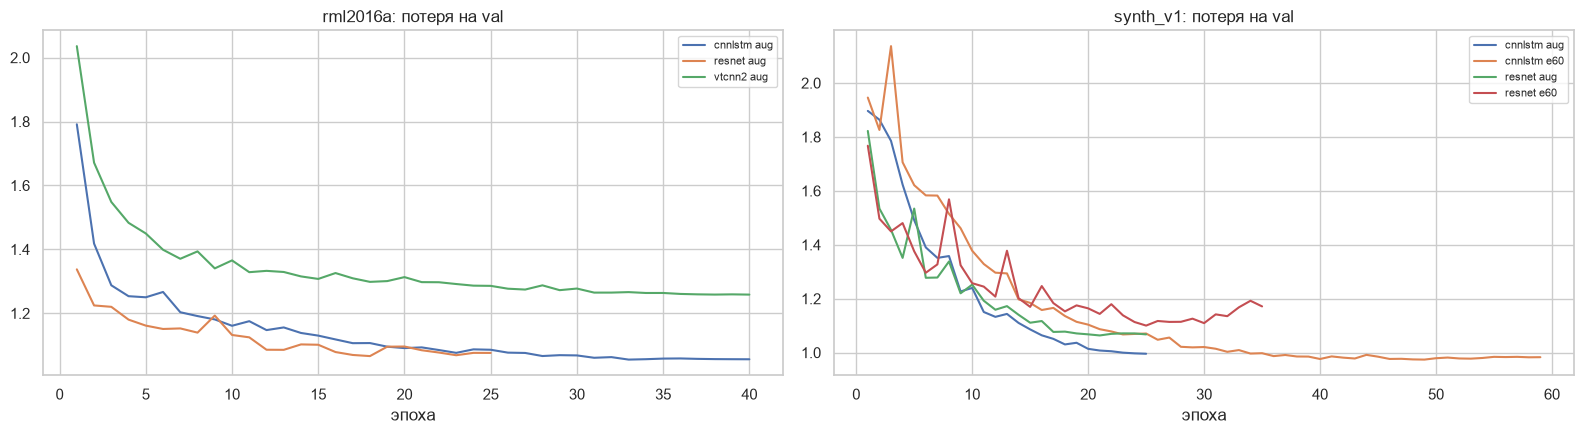

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, data in zip(axes, ["rml2016a", "synth_v1"]):
    for _, r in R[(R.data == data) & (R.seed == 0) & R.aug & (R.input == "iq")].iterrows():
        h = pd.DataFrame(r["history"])
        ax.plot(h["epoch"], h["val_loss"], label=f"{r['model']} {r['group'].split('_')[-1]}")
    ax.set_title(f"{data}: потеря на val")
    ax.set_xlabel("эпоха")
    ax.legend(fontsize=8)
plt.tight_layout()
savefig("learning_curves")
plt.show()

## 3. Accuracy в зависимости от ОСШ (тест; нейросети — среднее по seed'ам)

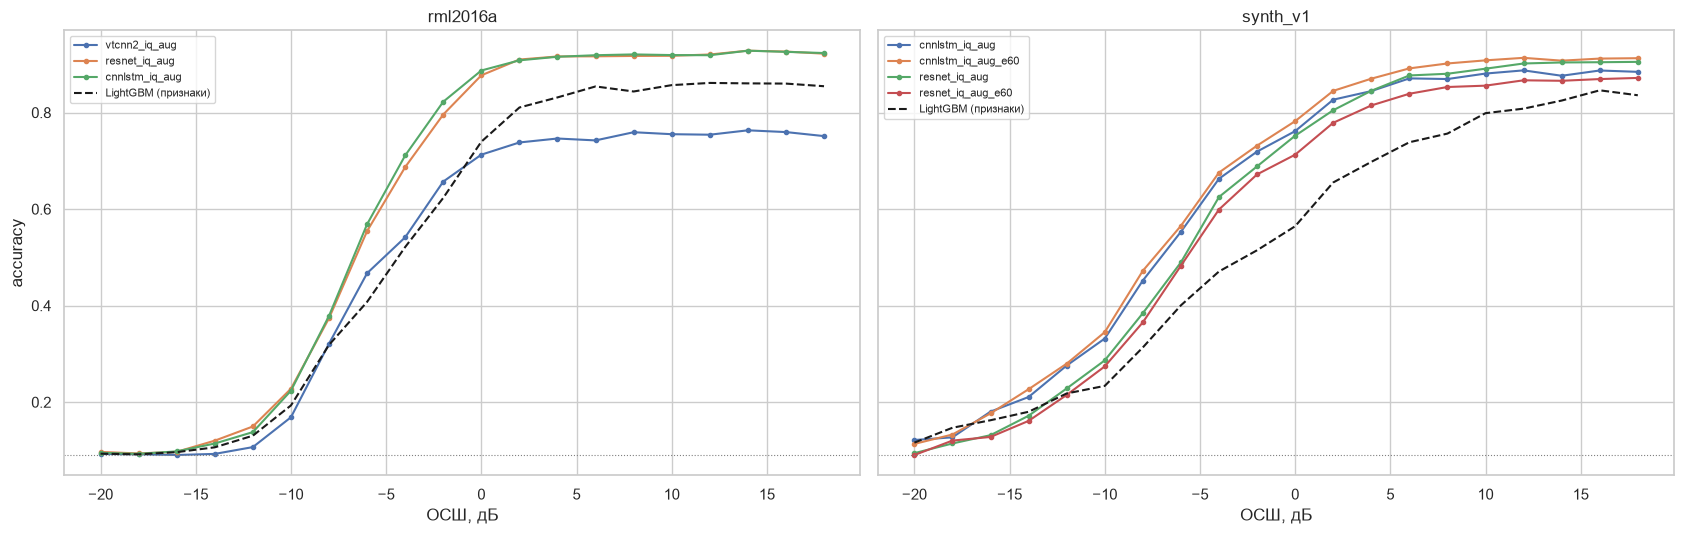

In [4]:
def snr_curve(proba: np.ndarray, d: dict) -> pd.Series:
    te = d["split"] == "test"
    return acc_by_snr(d["label"][te], proba.argmax(1)[te], d["snr"][te])


main_groups = {"rml2016a": ["rml2016a_vtcnn2_iq_aug", "rml2016a_resnet_iq_aug", "rml2016a_cnnlstm_iq_aug"],
               "synth_v1": sorted(g for g in R.group.unique() if g.startswith("synth_v1_") and "_128" not in g
                                  and "_iq_aug" in g)}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for ax, data in zip(axes, main_groups):
    d0 = None
    for g in main_groups[data]:
        curves = []
        for run in R[R.group == g].run:
            d0 = load_proba(run)
            curves.append(snr_curve(d0["proba"], d0))
        if curves:
            pd.concat(curves, axis=1).mean(axis=1).plot(ax=ax, marker="o", ms=3, label=g.replace(data + "_", ""))
    if d0 is not None and data in lgbm:
        b = baseline(data)
        snr_curve(b["proba"], {**b, "snr": d0["snr"]}).plot(ax=ax, ls="--", c="k", label="LightGBM (признаки)")
    ax.axhline(1 / 11, c="gray", lw=0.8, ls=":")
    ax.set_title(data)
    ax.set_xlabel("ОСШ, дБ")
    ax.legend(fontsize=8)
axes[0].set_ylabel("accuracy")
plt.tight_layout()
savefig("acc_vs_snr")
plt.show()

## 4. Статистическая значимость

- **Критерий Мак-Немара** — парное сравнение двух моделей на одних и тех же тестовых примерах
  (учитывает только расхождения: где одна права, а другая нет).
- **Парный бутстреп разности accuracy** (2000 повторов по тестовым примерам) — 95 % доверительный интервал
  величины улучшения.
- Разброс по seed'ам (СКО в таблице п. 1) показывает устойчивость обучения; три seed'а слишком мало для
  критерия Уилкоксона по seed'ам (минимально достижимое p = 0,25), поэтому значимость проверяется по примерам.

In [5]:
def compare(run_a: str, run_b: str | None, name_b: str = "", base: str | None = None) -> dict:
    """Мак-Немар и бутстреп-ДИ разности accuracy (a − b) на тесте."""
    a = load_proba(run_a)
    te = a["split"] == "test"
    y = a["label"][te]
    ca = a["proba"].argmax(1)[te] == y
    pb = baseline(base)["proba"] if base else load_proba(run_b)["proba"]
    cb = pb.argmax(1)[te] == y
    tbl = [[np.sum(ca & cb), np.sum(ca & ~cb)], [np.sum(~ca & cb), np.sum(~ca & ~cb)]]
    rng = np.random.default_rng(0)
    diff = ca.astype(float) - cb.astype(float)
    boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
    return {"A": run_a, "B": name_b or run_b, "acc A": ca.mean(), "acc B": cb.mean(), "Δ": diff.mean(),
            "ДИ 95 % Δ": f"[{np.quantile(boots, 0.025):+.4f}; {np.quantile(boots, 0.975):+.4f}]",
            "p Мак-Немар": mcnemar(tbl, exact=False, correction=True).pvalue}


tests = [
    compare("rml2016a_cnnlstm_iq_aug_s0", None, "LightGBM", base="rml2016a"),
    compare("rml2016a_resnet_iq_aug_s0", None, "LightGBM", base="rml2016a"),
    compare("rml2016a_vtcnn2_iq_aug_s0", None, "LightGBM", base="rml2016a"),
    compare("rml2016a_cnnlstm_iq_aug_s0", "rml2016a_resnet_iq_aug_s0"),
]
best_synth = R[R.data == "synth_v1"].groupby("group")["val_acc"].mean().idxmax()  # выбор по val, не по тесту
best_synth_run = R[(R.group == best_synth) & (R.seed == 0)].run.iloc[0]
tests.append(compare(best_synth_run, None, "LightGBM", base="synth_v1"))
other = [g for g in main_groups["synth_v1"] if g != best_synth]
for g in other:
    rr = R[(R.group == g) & (R.seed == 0)].run
    if len(rr):
        tests.append(compare(best_synth_run, rr.iloc[0]))
pd.DataFrame(tests)

,A,B,acc A,acc B,Δ,ДИ 95 % Δ,p Мак-Немар
0,rml2016a_cnnlstm_iq_aug_s0,LightGBM,0.620114,0.547727,0.072386,[+0.0689; +0.0758],0.000000e+00
1,rml2016a_resnet_iq_aug_s0,LightGBM,0.615864,0.547727,0.068136,[+0.0647; +0.0717],3.357676e-303
2,rml2016a_vtcnn2_iq_aug_s0,LightGBM,0.509932,0.547727,-0.037795,[-0.0416; -0.0336],5.106111e-81
3,rml2016a_cnnlstm_iq_aug_s0,rml2016a_resnet_iq_aug_s0,0.620114,0.615864,0.004250,[+0.0019; +0.0065],3.380859e-04
4,synth_v1_cnnlstm_iq_aug_s0_e60,LightGBM,0.628983,0.514478,0.114505,[+0.1100; +0.1193],0.000000e+00
5,synth_v1_cnnlstm_iq_aug_s0_e60,synth_v1_cnnlstm_iq_aug_s0,0.628983,0.611596,0.017387,[+0.0139; +0.0208],4.078001e-23
6,synth_v1_cnnlstm_iq_aug_s0_e60,synth_v1_resnet_iq_aug_s0,0.628983,0.595845,0.033138,[+0.0293; +0.0369],5.808746e-65
7,synth_v1_cnnlstm_iq_aug_s0_e60,synth_v1_resnet_iq_aug_s0_e60,0.628983,0.576822,0.052161,[+0.0483; +0.0560],2.004548e-142


## 5. Абляции (RadioML, ResNet-1D, seed 0)

In [6]:
abl = []
for run, what in [("rml2016a_resnet_iq_noaug_s0", "без аугментаций"), ("rml2016a_resnet_ap_aug_s0", "вход: амплитуда + частота"),
                  ("rml2016a_resnet_iqap_aug_s0", "вход: I/Q + амплитуда + частота")]:
    if (DEEP / run).exists():
        r = compare("rml2016a_resnet_iq_aug_s0", run)
        r["вариант B"] = what
        abl.append(r)
pd.DataFrame(abl)[["вариант B", "acc A", "acc B", "Δ", "ДИ 95 % Δ", "p Мак-Немар"]]

,вариант B,acc A,acc B,Δ,ДИ 95 % Δ,p Мак-Немар
0,без аугментаций,0.615864,0.603523,0.012341,[+0.0089; +0.0158],5.511066e-12
1,вход: амплитуда + частота,0.615864,0.604205,0.011659,[+0.0092; +0.0141],2.334282e-19
2,вход: I/Q + амплитуда + частота,0.615864,0.616795,-0.000932,[-0.0032; +0.0015],4.652832e-01


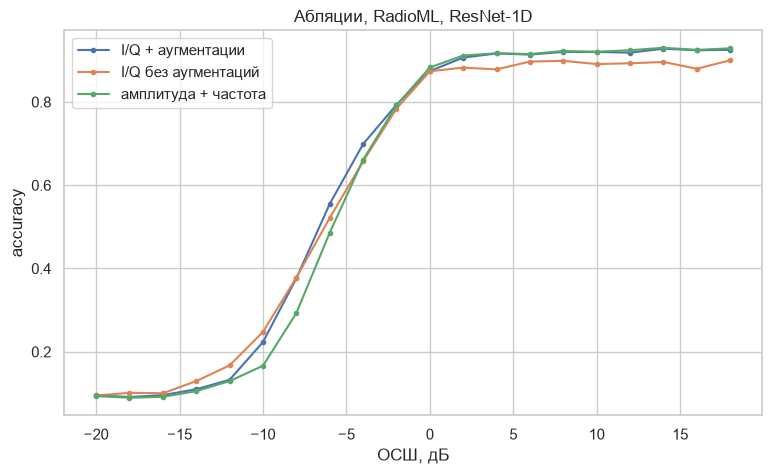

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for run, lab in [("rml2016a_resnet_iq_aug_s0", "I/Q + аугментации"), ("rml2016a_resnet_iq_noaug_s0", "I/Q без аугментаций"),
                 ("rml2016a_resnet_ap_aug_s0", "амплитуда + частота")]:
    d = load_proba(run)
    snr_curve(d["proba"], d).plot(ax=ax, marker="o", ms=3, label=lab)
ax.set_xlabel("ОСШ, дБ")
ax.set_ylabel("accuracy")
ax.set_title("Абляции, RadioML, ResNet-1D")
ax.legend()
savefig("ablation")
plt.show()

## 5б. Длительность обучения: 25 против 60 эпох (свой датасет)
Первая очередь обучалась с бюджетом 25 эпох (терпение 7): все запуски дошли до конца бюджета, val loss ещё падал —
похоже на недообучение. Вторая очередь — бюджет 60 эпох, терпение 10 (ранняя остановка по val loss).
Расписание OneCycle растягивается на весь бюджет: при бюджете 25 скорость обучения к концу полностью «отжигается»,
при бюджете 60 и раннем останове — останавливается на высокой скорости. Проверяется, что важнее.
Сравнение парное: тот же seed, те же примеры теста; Мак-Немар + бутстреп-ДИ разности.

In [8]:
ep = []
for model in ["resnet", "cnnlstm"]:
    for seed in range(3):
        a, b = f"synth_v1_{model}_iq_aug_s{seed}_e60", f"synth_v1_{model}_iq_aug_s{seed}"
        if (DEEP / a).exists() and (DEEP / b).exists():
            r = compare(a, b)
            ra, rb = R.set_index("run").loc[a], R.set_index("run").loc[b]
            r.update({"модель": model, "seed": seed, "эпох (60)": ra["epochs_run"], "эпох (25)": rb["epochs_run"],
                      "val acc (60)": ra["val_acc"], "val acc (25)": rb["val_acc"]})
            ep.append(r)
EP = pd.DataFrame(ep)
EP[["модель", "seed", "эпох (25)", "эпох (60)", "val acc (25)", "val acc (60)", "acc B", "acc A", "Δ", "ДИ 95 % Δ",
    "p Мак-Немар"]].rename(columns={"acc A": "test acc (60)", "acc B": "test acc (25)"}).round(4)

,модель,seed,эпох (25),эпох (60),val acc (25),val acc (60),test acc (25),test acc (60),Δ,ДИ 95 % Δ,p Мак-Немар
0,resnet,0,25,35,0.5938,0.5749,0.5958,0.5768,-0.0190,[-0.0224; -0.0155],0.0
1,resnet,1,25,35,0.5931,0.5730,0.5961,0.5742,-0.0219,[-0.0255; -0.0185],0.0
2,resnet,2,25,30,0.5880,0.5651,0.5913,0.5656,-0.0257,[-0.0292; -0.0221],0.0
3,cnnlstm,0,25,59,0.6131,0.6297,0.6116,0.6290,0.0174,[+0.0139; +0.0208],0.0


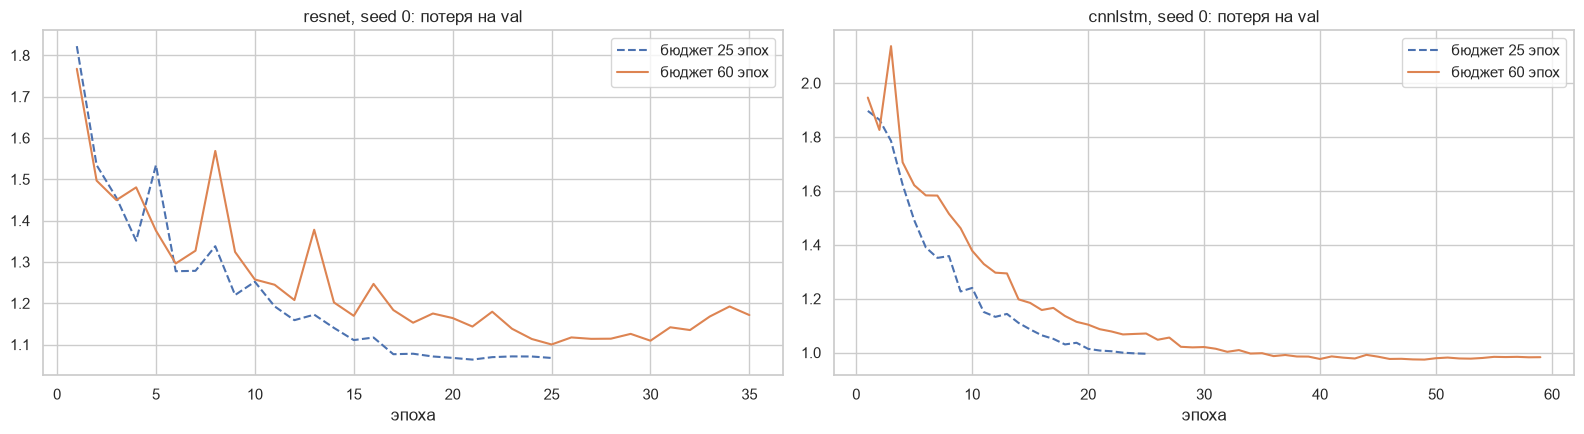

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, model in zip(axes, ["resnet", "cnnlstm"]):
    for suf, ls in [("", "--"), ("_e60", "-")]:
        run = f"synth_v1_{model}_iq_aug_s0{suf}"
        if run in set(R.run):
            h = pd.DataFrame(R.set_index("run").loc[run, "history"])
            ax.plot(h["epoch"], h["val_loss"], ls=ls, label=f"бюджет {'60' if suf else '25'} эпох")
    ax.set_title(f"{model}, seed 0: потеря на val")
    ax.set_xlabel("эпоха")
    ax.legend()
plt.tight_layout()
savefig("epochs_budget")
plt.show()

## 6. Матрицы ошибок лучших моделей (ОСШ ≥ 10 дБ)

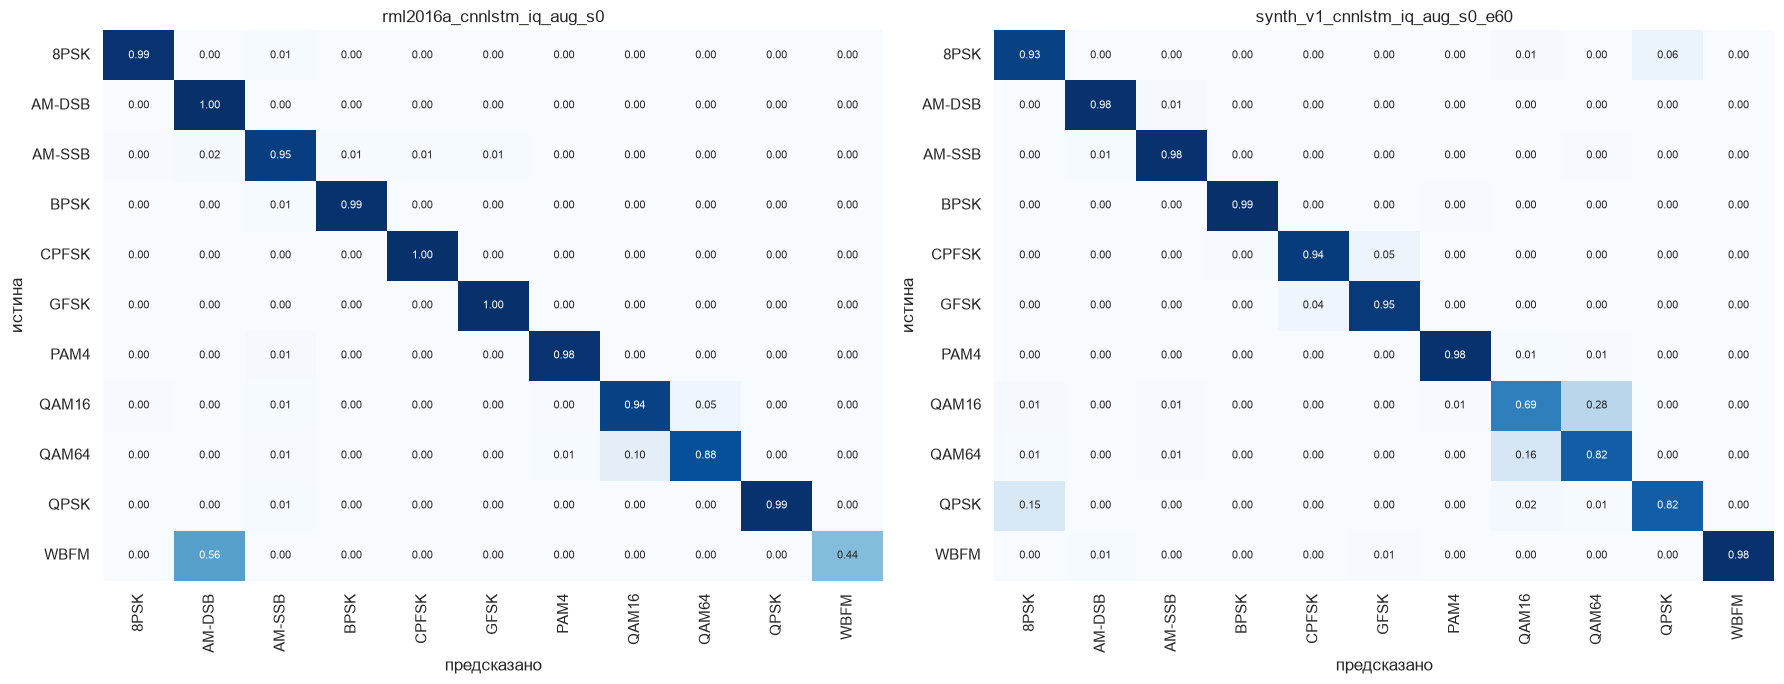

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, run in zip(axes, ["rml2016a_cnnlstm_iq_aug_s0", best_synth_run]):
    d = load_proba(run)
    m = (d["split"] == "test") & (d["snr"] >= 10)
    cm = confusion_matrix(d["label"][m], d["proba"].argmax(1)[m], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False,
                annot_kws={"size": 8})
    ax.set_title(run)
    ax.set_xlabel("предсказано")
    ax.set_ylabel("истина")
plt.tight_layout()
savefig("confusion_best")
plt.show()

## 7. Эмбеддинги (UMAP)
Последний слой ResNet-1D перед классификатором для 4000 тестовых примеров RadioML при ОСШ ≥ 10 дБ,
сжатый в 2D методом UMAP. Если классы образуют отдельные облака — сеть выучила разделимое представление;
слипшиеся облака — пары, которые сеть путает.

<site-packages>\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<site-packages>\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


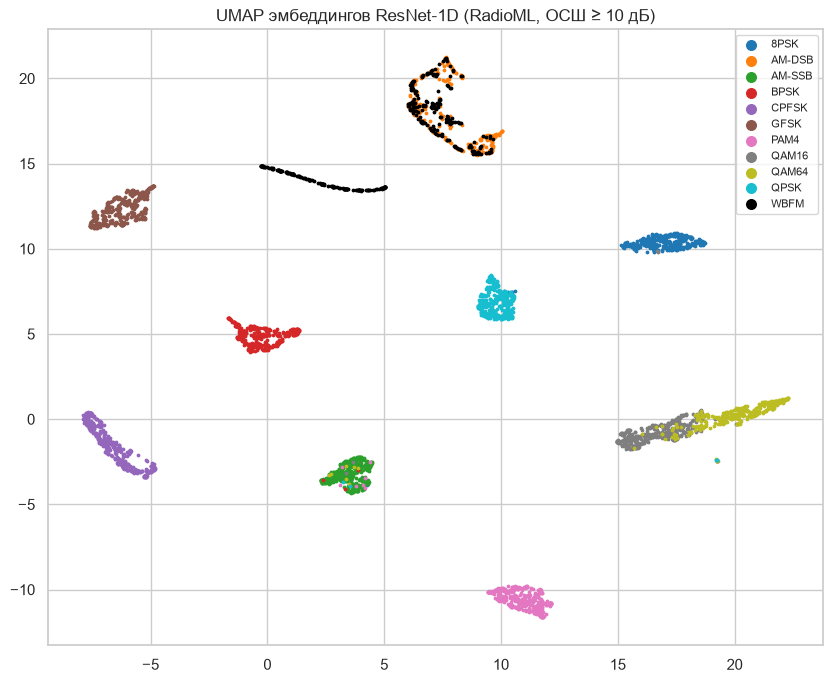

In [11]:
import umap  # noqa: E402

from amc.data import load_rml2016a  # noqa: E402

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X, meta, _ = load_rml2016a()
idx = np.flatnonzero((meta["split"] == "test").to_numpy() & (meta["snr_db"] >= 10).to_numpy())
idx = np.random.default_rng(0).choice(idx, 4000, replace=False)
model = build("resnet", 2, 11, 128).to(dev)
model.load_state_dict(torch.load(DEEP / "rml2016a_resnet_iq_aug_s0" / "model.pt", map_location=dev))
model.eval()
with torch.no_grad():
    emb = model.encode(represent(normalize_power(torch.from_numpy(X[idx]).to(dev)), "iq")).float().cpu().numpy()
xy = umap.UMAP(random_state=0).fit_transform(emb)
plt.figure(figsize=(10, 8))
lab = meta["cls"].to_numpy()[idx]
PAL = sns.color_palette("tab10") + [(0.0, 0.0, 0.0)]  # 11 классов — 11 различимых цветов (в tab10 их 10)
for c in CLASSES:
    m = lab == c
    plt.scatter(xy[m, 0], xy[m, 1], s=3, label=c, color=PAL[CLASSES.index(c)])
plt.legend(markerscale=4, fontsize=8)
plt.title("UMAP эмбеддингов ResNet-1D (RadioML, ОСШ ≥ 10 дБ)")
savefig("umap")
plt.show()

## 8. Выводы

1. **Нейросети на сырых I/Q лучше экспертных признаков.** RadioML: CNN-LSTM 62,0 ± 0,3 % (ОСШ ≥ 0: 91,7 %) и
   ResNet-1D 61,7 ± 0,1 % (91,5 %) против LightGBM 54,8 % (83,7 %): +7,2 п.п., ДИ 95 % [+6,9; +7,6],
   Мак-Немар p < 1e-300. Свой датасет: CNN-LSTM 62,9 ± 0,1 % (88,4 %) против LightGBM 51,4 % (75,3 %):
   +11,5 п.п. [+11,0; +11,9]. Результаты на RadioML соответствуют литературе для этого датасета (≈ 60–62 %).
2. **Классическая VT-CNN2 хуже бустинга** (50,6 % против 54,8 %, p ≈ 5e-81): 2,8 млн параметров в плотных слоях
   переобучаются, а свёрточная часть слишком мелкая. Архитектура важнее размера: CNN-LSTM с 0,28 млн параметров —
   лучшая модель на обоих датасетах.
3. **CNN-LSTM против ResNet-1D** на RadioML: +0,4 п.п. [+0,2; +0,7], p = 3e-4 — значимо, но практически мало; на
   своём датасете (длинные окна 1024 отсчёта) разница больше: +3,3 п.п. [+2,9; +3,7] — рекуррентная часть
   накапливает информацию по многим символам.
4. **Аугментации** (поворот фазы, сдвиг частоты, инверсия спектра) дают +1,2 п.п. [+0,9; +1,6], p = 6e-12, и,
   главное, устойчивость к сдвигу частоты и инверсии (см. 04). **Представление входа:** амплитуда+частота
   хуже I/Q на 1,2 п.п. (p = 2e-19); I/Q + амплитуда + частота = I/Q (p = 0,47) — сеть сама вычисляет эти признаки.
5. **Длительность обучения (25 против 60 эпох)** зависит от ёмкости модели: ResNet (1,28 млн) при бюджете 60
   переобучается (train loss 0,83, val loss растёт с 25-й эпохи) и останавливается на высокой скорости
   обучения OneCycle — test хуже на 1,9–2,6 п.п. для всех трёх seed'ов (p < 1e-4); CNN-LSTM (0,28 млн)
   выигрывает +1,7 п.п. [+1,4; +2,1]. Короткий бюджет с полным «отжигом» скорости работает как регуляризация.
   Финальные модели выбирались **по val**, не по тесту.
6. **Длина окна решает**: на своём датасете ResNet с окном 128 отсчётов — 42,5 %, с окном 1024 — 59,4 %.
   Для продукта выбраны окна 1024 (с агрегацией по окнам в файле).
7. **Матрицы ошибок** (ОСШ ≥ 10 дБ). RadioML: WBFM → AM-DSB 56 % (дефект датасета, см. 01_eda: оба класса —
   практически немодулированная несущая/тон), QAM64 → QAM16 10 %; остальные классы ≥ 94 %. Свой датасет:
   QAM16 ↔ QAM64 (28 % и 16 %), QPSK → 8PSK 15 % (многолучёвость и фазовый шум «размывают» созвездие),
   CPFSK ↔ GFSK 4–5 %; аналоговые ≥ 98 % — в своём генераторе они различимы, в отличие от RadioML.
   UMAP-проекция эмбеддингов RadioML показывает те же пары слипшимися облаками (AM-DSB+WBFM, QAM16+QAM64,
   AM-SSB с примесью шумоподобных примеров), остальные классы — отдельные компактные облака.
8. **Разброс по seed'ам** мал (СКО 0,1–0,6 п.п.), то есть различия между архитектурами (≥ 0,4 п.п.)
   больше шума обучения, а выводы воспроизводимы.